# 2 Ising model

## Monte Carlo method

<div style="background-color: #f0f8ff; border: 2px solid #4682b4; padding: 10px;">
    
**Note:** This notebook contains the code for section 2.1 from the book
    
**Simulation of Complex Systems**
Aykut Argun, Agnese Callegari, and Giovanni Volpe<br>
IOP Publishing, Bristol, UK, 2021<br>
ISBN: 978-0-7503-3843-1<br>
[https://iopscience.iop.org/book/mono/978-0-7503-3843-1](https://iopscience.iop.org/book/mono/978-0-7503-3843-1)
    
    
You can find the other notebooks on the [Simulation of Complex Systems GitHub page](../../)
</div>

Ising model: simple model for ferromagnetism.

Standard tool to understand magnetization and phase transitions.

Simulation method: Monte Carlo.

**Historical reading:** H. A. Kramers (1940), [*Brownian motion in a field of force and the diffusion model of chemical reactions*](https://doi.org/10.1016/S0031-8914(40)90098-2), *Physica* **7**, 284–304. This paper motivates the barrier-crossing problem; the discrete model below is a simplification.

<a id="boltzmann"></a>
### 2.1 Monte Carlo method — Boltzmann probabilities

For states with energies $E_i$, canonical equilibrium probabilities are (textbook Eq. 2.1)

$$p_i=\frac{1}{Z} e^{-\frac{E_i}{k_BT}},\qquad Z=\sum_i e^{-\frac{E_i}{k_BT}}.$$

The Boltzmann constant $k_B$: converts temperature to an energy scale. 

Here: $k_B=1$.

**Note:** Monte Carlo steps are *not* physical time.

In [12]:
import numpy as np
import matplotlib.pyplot as plt

**Exercise 2.1:**
Three-state system.

Left $\leftrightarrow$ Middle $\leftrightarrow$ Right. 

The two end states have zero energy and the middle state is a barrier of height $E_b$.

In [13]:
states = np.array(["Left", "Middle", "Right"])
barrier = 2.0
kB = 1.0
T = 1.0
energies = np.array([0.0, barrier, 0.0])  

We calculate the Boltzmann distribution (probabilities for each state)

Probabilities:
{'Left': 0.468, 'Middle': 0.063, 'Right': 0.468}


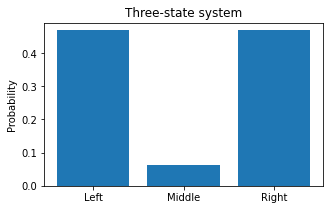

In [14]:
weights = np.exp(-energies / (kB * T))
Z = np.sum(weights)
probabilities = weights / Z

print('Probabilities:')
print(dict(zip(states, np.round(probabilities, 3))))

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(states, probabilities)
ax.set_ylabel("Probability")
ax.set_title("Three-state system")
plt.show()

Here we plot the energies:

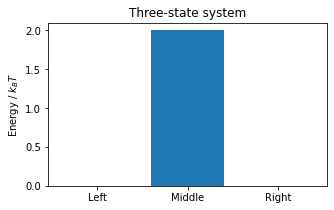

In [15]:
fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(states, energies)
ax.set_ylabel("Energy / $k_B T$")
ax.set_title("Three-state system")
plt.show()

<a id="transitions"></a>
### Stochastic transitions and detailed balance

Transitions: only between neighboring states. 

Note that now we identify the states with their indices:  <br>
0 ("Left") <br>
1 ("Middle") <br>
2 ("Right") <br>

Let's illustrate the procedure. 
We start from the "Left" state.

In [16]:
rng = np.random.default_rng()  

current_state = 0  # Left

In [17]:
attempted_direction = rng.choice([-1, 1])

proposed_state = current_state + attempted_direction

print(f"Proposed state index: {proposed_state}")  

if 0 <= proposed_state < len(states):
    energy_change = (
        energies[proposed_state] - energies[current_state]
    )
    acceptance = min(1.0, np.exp(-energy_change / (kB * T)))
    if rng.random() < acceptance:
        current_state = proposed_state
        
print("State after one proposal:", states[current_state])

Proposed state index: 1
State after one proposal: Middle


A trajectory is produced by repeating *exactly* the same logic. 

In [18]:
n_steps = 30_000
current_state = 0
trajectory = np.empty(n_steps, dtype=int)
trajectory[0] = current_state

for step in range(n_steps - 1):
    proposed_state = current_state + rng.choice([-1, 1])
    if 0 <= proposed_state < 3:
        energy_change = (
            energies[proposed_state] - energies[current_state]
        )
        if rng.random() < min(1.0, np.exp(-energy_change / (kB * T))):
            current_state = proposed_state
    trajectory[step + 1] = current_state

Let's plot the trajectory:

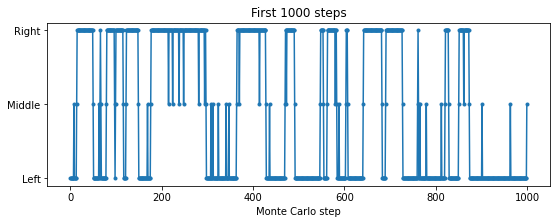

In [19]:
n_plot = 1000  # firs n_plot points

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(np.arange(n_plot), trajectory[:n_plot], '.-')
ax.set(
    yticks=[0, 1, 2], 
    yticklabels=states, 
    xlabel="Monte Carlo step", 
    title=f"First {n_plot} steps"
)
plt.show()

<a id="equilibrium"></a>
Let's plot the empirical distribution

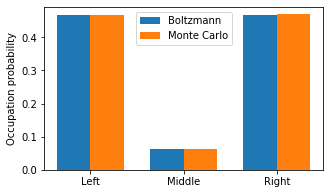

In [20]:
n_discard = 3000  
occupation = np.bincount(trajectory[n_discard:], minlength=3)
empirical_probabilities = occupation / occupation.sum()

fig, ax = plt.subplots(figsize=(5, 3))
x = np.arange(3)
ax.bar(x - 0.18, probabilities, width=0.36, label="Boltzmann")
ax.bar(x + 0.18, empirical_probabilities, 
       width=0.36, label="Monte Carlo")
ax.set(
    xticks=x, 
    xticklabels=states, 
    ylabel="Occupation probability"
)
ax.legend()
plt.show()

<a id="escape-times"></a>
### Escape times and the energy barrier

We attemp to measure the number of Monte Carlo steps needed to reach Right starting from Left. 

Each run is an independent stochastic realization. 

The escape time here is in **MC steps**, not seconds.

In [21]:
barriers = [0.5, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0] 
mean_escape = []
n_trials = 250
for barrier in barriers:
    energies = np.array([0.0, barrier, 0.0])
    escape_times = []
    for trial in range(n_trials):
        state = 0
        steps = 0
        while state != 2:
            proposal = state + rng.choice([-1, 1])
            if 0 <= proposal < 3:
                difference = energies[proposal] - energies[state]
                if (
                    rng.random() < 
                    min(1.0, np.exp(-difference / (kB * T)))
                ):
                    state = proposal
            steps += 1
        escape_times.append(steps)
    mean_escape.append(np.mean(escape_times))

Let's plot the escape time

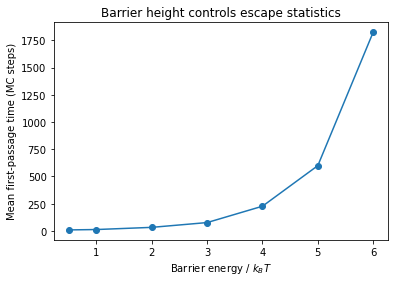

In [24]:
plt.plot(barriers, mean_escape, "o-")
plt.xlabel("Barrier energy / $k_B T$")
plt.ylabel("Mean first-passage time (MC steps)")
plt.title("Barrier height controls escape statistics")
# plt.yscale("log")     
plt.show()



<a id="questions"></a>

## Questions

Here you find the questions:

- [Q1: Boltzmann weights](#q1)
- [Q2: Allowed transitions](#q2)
- [Q3: Update and equilibrium](#q3)
- [Q4: Escape-time variability](#q4)

<a id="q1"></a>
**Question 1:** Generalities on Boltzmann distribution and weights

Refer to: [Boltzmann distribution](#boltzmann)

[Go back to questions](#questions)

Consider the command:
```python
u = dict(zip(states, np.round(probabilities, 3)))
```
where `states = np.array(["Left", "Middle", "Right"])` and 
`probabilities = np.array([0.4, 0.2, 0.4])`

a. What is the outcome of: `print(type(u))`?

b. What is the outcome of: `print(u[0])` ?

c. What is the outcome of: `print(u['Left'])` ?

d. You have `energies = np.array([0.0, barrier, 0.0])`. You define: `e10 = np.array([0.0, barrier, 0.0]) + 10.0` . You calculate `p10`, the Boltzmann probabilities of for `e10`. How do `p10` compare with `probabilities` (the Boltzmann probabilities of for `energies`)?

e. Consider the Boltzmann formula. What happens to the probabilities  as $T\to\infty$? 


f. Write the implementation for a system with 5 states, called "0", "1", "2", "3", "4" and energies: 
`energies = np.array([0.0, barrier, 0.0, barrier, 0.0])`

<a id="q2"></a>
**Question 2:** Allowed transitions.

Refer to: [Allowed transitions](#transitions)

[Go back to questions](#questions)

Consider the lines:
```python
current_state = 2  # Right
attempted_direction = rng.choice([-1, 1])
proposed_state = current_state + attempted_direction
```
in the current three-states system.

a. Instead of `print(f"Proposed state index: {proposed_state}")` you want to write:
```python
print(f"Proposed state: {states[proposed_state]}")
```
because you want it's written either "Left", "Middle", or "Right".
Is this a good idea?

b. In the case `current_state = 1  # Middle` is the line
```python
print(f"Proposed state: {states[proposed_state]}")
```
problematic? Why or why not?


<br>Consider a different way to approach the task of generating a trajectory. This time, we choose at random:
```python
proposed_state = rng.choice(range(3))
```
If the proposed_state is not allowed by the transition rule, we set 
`proposed_state = current_state`
If the proposed_state is allowed by the transition rule, we draw a number at random `p = rng.random()` and we transition to the proposed_state only when `p <= probabilities[proposed_state]`.

c. Write a short implementation of this algorithm.

d. It this new algorithm equivalent to the one implemented above? How would you verify this?


<a id="q3"></a>
**Question 3:** Empirical distribution and equilibrium

Refer to: [Empirical distribution](#equilibrium)


[Go back to questions](#questions)

Consider the lines:
```python
n_discard = 3000  
occupation = np.bincount(trajectory[n_discard:], minlength=3)
```

a. Why we decided to discard `n_discard` points from the trajectory?

b. What is the outcome of `type(occupation)`? 

c. What is the outcome of `occupation.shape`? 

d. Assume we had: `occupation = np.bincount(trajectory[n_discard:])` (i.e., omitting `, minlength=3`). Are we sure that, in the current setting, we always have `occupation.size` equal to 3?


We define: 
```python
new_occupation = np.bincount(trajectory[n_discard:] + 1, minlength=3)
```

e. Assume `print(occupation)` gives `[10   10   0]`.
What is the outcome of `print(new_occupation)` ?

f. Assume `print(occupation)` gives `[10   0   10]`.
What is the outcome of `print(new_occupation)` ?


<a id="q4"></a>
**Question 4:** Escape time

Refer to: [Escape times](#escape-times)

[Go back to questions](#questions)

a. Why do independently repeated simulations give different first-passage times?


<br>Suppose you have a 5-states system:
```
states = np.array(["0", "1", "2", "3", "4"])
barrier = 1.5
kB = 1.0
T = 1.0
energies = np.array([0.0, barrier, 0.0, barrier, 0.0])  
```

b. Modify the algorithm for the escape time to calculate the escape for a particle set in "0" to escape to "4".


Run the code and estimate the escape time from "0" to "4" (`t_esc_0_4`). 

c. Is it longer or shorter than the escape time from "0" to "2"?

d. Is it longer or shorter than the escape time from "4" to "0"?


In this 5-states system, now you have: `energies = np.array([0.0, 2 * barrier, 0.0, 0.0, 0.0])  `
Run the code and estimate the escape time from "0" to "4" (`t_esc_0_4`). 

e. Is it longer or shorter than the escape time from "0" to "2"?

f. Is it longer or shorter than the escape time from "4" to "0"?

